In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
CUDA: True


In [2]:
train_transforms = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),

    transforms.Resize((48, 48)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])


test_transforms = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),

    transforms.Resize((48, 48)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])

In [3]:
PROJECT_ROOT = Path.cwd().parent

TRAIN_DIR = PROJECT_ROOT / "data" / "train"
TEST_DIR = PROJECT_ROOT / "data" / "test"

train_dataset = ImageFolder(
    root=TRAIN_DIR,
    transform=train_transforms
)

test_dataset = ImageFolder(
    root=TEST_DIR,
    transform=test_transforms
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

print("Emotion classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Training images: 28709
Testing images: 7178
Emotion classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [4]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 449
Testing batches: 113


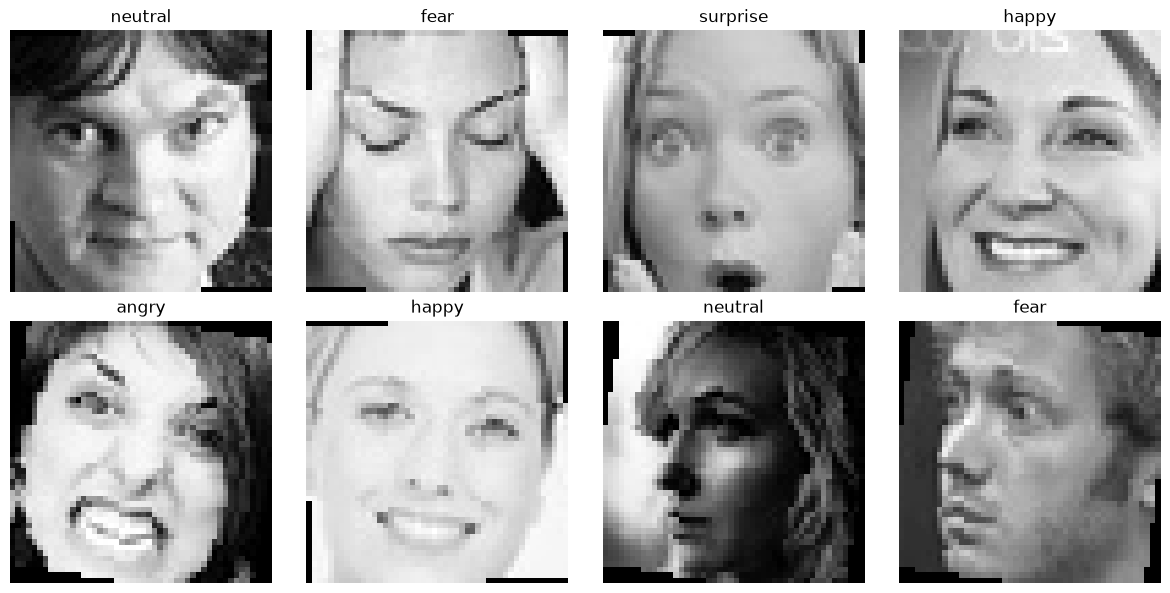

Batch shape: torch.Size([64, 1, 48, 48])
Label shape: torch.Size([64])


In [5]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    image = images[i].squeeze().numpy()

    # Undo normalization for visualization
    image = image * 0.5 + 0.5

    ax.imshow(image, cmap="gray")
    ax.set_title(train_dataset.classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Batch shape:", images.shape)
print("Label shape:", labels.shape)